# Applications VI: Electromagnetism

- [A6.1 Magnetic fields from Biot-Savart: Helmholtz coils](#biot-savart) - *quadrature (Ch. 4)*
- [A6.2 Charged particles in fields: the Boris pusher](#boris) - *symplectic-style integrators (Ch. 5)*
- [A6.3 A magnetic bottle](#bottle) - *ODEs (Ch. 5)*
- [A6.4 Capacitance with a sparse Poisson solver](#capacitor) - *finite differences, sparse linear algebra (Ch. 6, 7)*
- [A6.5 Light in a box: the FDTD method for Maxwell's equations](#fdtd) - *leapfrog PDE solver (Ch. 7)*
- [Projects](#projects)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse.linalg import spsolve

mu0, eps0 = 4e-7*np.pi, 8.8541878128e-12

# A6.1 Magnetic fields from Biot-Savart: Helmholtz coils <a class="anchor" id="biot-savart"></a>
The field of a current-carrying wire is

$$\mathbf B(\mathbf r) = \frac{\mu_0 I}{4\pi}\oint\frac{d\mathbf l\times(\mathbf r - \mathbf r')}{|\mathbf r-\mathbf r'|^3}.$$

Off the axis of a circular loop this integral gives elliptic integrals - not pleasant. Numerically, it's easy: chop the wire into $N$ short straight segments and add up their contributions (the midpoint rule, Chapter 4). Because the integrand is smooth and periodic around the loop, this converges *exponentially* fast in $N$ - the same reason the trapezium rule is spectacular for periodic functions.

A **Helmholtz coil** is a pair of identical coaxial loops separated by exactly their radius $R$. That spacing makes the second derivative of $B_z$ vanish at the centre, giving a very uniform field - used to cancel the Earth's field in labs and to calibrate magnetometers.

In [2]:
def loop_segments(R, z0, N=200):
    phi = np.linspace(0, 2*np.pi, N, endpoint=False) + np.pi/N     # segment midpoints
    mid = np.stack([R*np.cos(phi), R*np.sin(phi), np.full(N, z0)], axis=1)
    dl = np.stack([-np.sin(phi), np.cos(phi), np.zeros(N)], axis=1)*2*np.pi*R/N
    return mid, dl

def biot_savart(points, wires, I=1.0):
    """points: (M, 3) field points. wires: list of (midpoints, dl) arrays."""
    B = np.zeros_like(points, dtype=float)
    for mid, dl in wires:
        d = points[:, None, :] - mid[None, :, :]                  # (M, N, 3)
        r3 = np.linalg.norm(d, axis=-1)[..., None]**3
        B += mu0*I/(4*np.pi)*np.sum(np.cross(dl[None], d)/r3, axis=1)
    return B

R, I = 0.1, 1.0
# On the axis, symmetry makes the segment sum exact for any N >= 3 - check against B = mu0 I R^2 / (2 (R^2 + z^2)^1.5)
z = np.linspace(-0.2, 0.2, 9)
Bz = biot_savart(np.column_stack([np.zeros_like(z), np.zeros_like(z), z]), [loop_segments(R, 0, 8)])[:, 2]
exact = mu0*I*R**2/(2*(R**2 + z**2)**1.5)
print(f'on axis, 8 segments: max relative error = {np.max(np.abs(Bz/exact - 1)):.1e}')

# Off axis there's no simple formula, so watch the convergence against a very fine reference
p = np.array([[0.06, 0.0, 0.03]])
B_ref = biot_savart(p, [loop_segments(R, 0, 20000)])
for N in [8, 16, 32, 64, 128]:
    err = np.linalg.norm(biot_savart(p, [loop_segments(R, 0, N)]) - B_ref)/np.linalg.norm(B_ref)
    print(f'off axis, N = {N:>3} segments: relative error = {err:.1e}')

on axis, 8 segments: max relative error = 4.4e-16
off axis, N =   8 segments: relative error = 2.5e-02
off axis, N =  16 segments: relative error = 2.2e-04
off axis, N =  32 segments: relative error = 1.2e-08
off axis, N =  64 segments: relative error = 4.3e-15
off axis, N = 128 segments: relative error = 4.5e-15


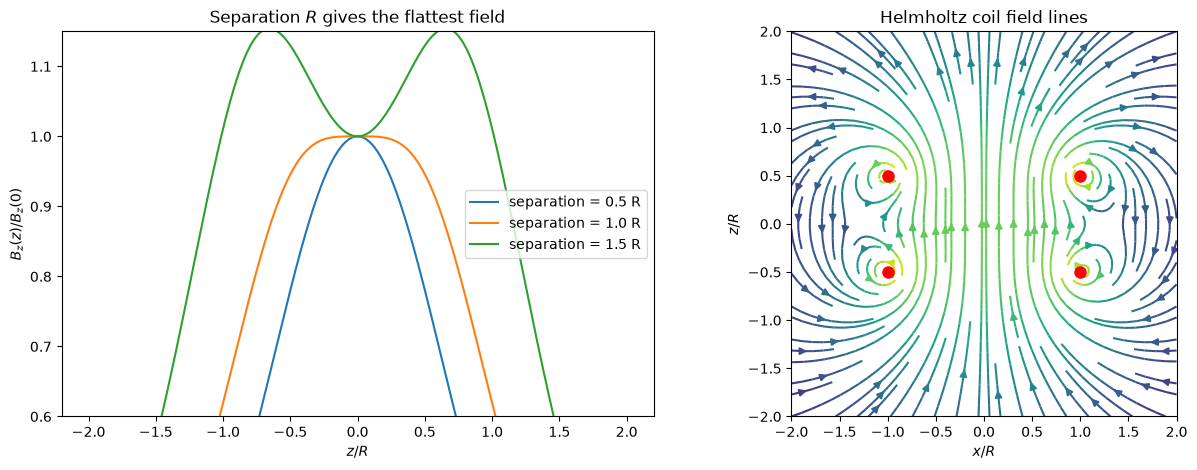

In [3]:
zs = np.linspace(-0.2, 0.2, 401)
pts = np.column_stack([np.zeros_like(zs), np.zeros_like(zs), zs])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for sep in [0.5*R, R, 1.5*R]:
    Bz = biot_savart(pts, [loop_segments(R, -sep/2), loop_segments(R, sep/2)])[:, 2]
    ax1.plot(zs/R, Bz/Bz[200], label=f'separation = {sep/R:.1f} R')
ax1.set_xlabel('$z/R$'); ax1.set_ylabel('$B_z(z)/B_z(0)$'); ax1.set_ylim(0.6, 1.15); ax1.legend()
ax1.set_title('Separation $R$ gives the flattest field')

# field lines in the x-z plane for the Helmholtz pair
X, Z = np.meshgrid(np.linspace(-0.2, 0.2, 41), np.linspace(-0.2, 0.2, 41))
P = np.column_stack([X.ravel(), np.zeros(X.size), Z.ravel()])
B = biot_savart(P, [loop_segments(R, -R/2), loop_segments(R, R/2)])
Bx, Bz = B[:, 0].reshape(X.shape), B[:, 2].reshape(X.shape)
ax2.streamplot(X/R, Z/R, Bx, Bz, density=1.2, color=np.log(np.hypot(Bx, Bz)), cmap='viridis')
for zc in [-0.5, 0.5]:
    ax2.plot([-1, 1], [zc, zc], 'ro', ms=8)
ax2.set_aspect('equal'); ax2.set_xlabel('$x/R$'); ax2.set_ylabel('$z/R$'); ax2.set_title('Helmholtz coil field lines')
plt.tight_layout(); plt.show()

# A6.2 Charged particles in fields: the Boris pusher <a class="anchor" id="boris"></a>
The Lorentz force law $m\dot{\mathbf v} = q(\mathbf E + \mathbf v\times\mathbf B)$ governs everything from cathode-ray tubes to the solar wind. A magnetic field does no work, so the particle's speed should stay constant - but a generic integrator like RK4 slowly gains or loses energy over many gyrations (exactly the problem we met in Chapter 5.6).

The **Boris algorithm** (1970), used in essentially every plasma simulation code, splits each step into: half an electric kick, a pure **rotation** of the velocity about $\mathbf B$, and another half electric kick. A rotation cannot change the speed, so in a pure magnetic field kinetic energy is conserved *exactly* - for any time step:

$$\mathbf v^- = \mathbf v^n + \tfrac{q\Delta t}{2m}\mathbf E,\quad
\mathbf t = \tfrac{q\Delta t}{2m}\mathbf B,\quad
\mathbf s = \frac{2\mathbf t}{1+t^2},\quad
\mathbf v' = \mathbf v^- + \mathbf v^-\times\mathbf t,\quad
\mathbf v^+ = \mathbf v^- + \mathbf v'\times\mathbf s,$$
$$\mathbf v^{n+1} = \mathbf v^+ + \tfrac{q\Delta t}{2m}\mathbf E,\qquad \mathbf x^{n+1} = \mathbf x^n + \Delta t\,\mathbf v^{n+1}.$$

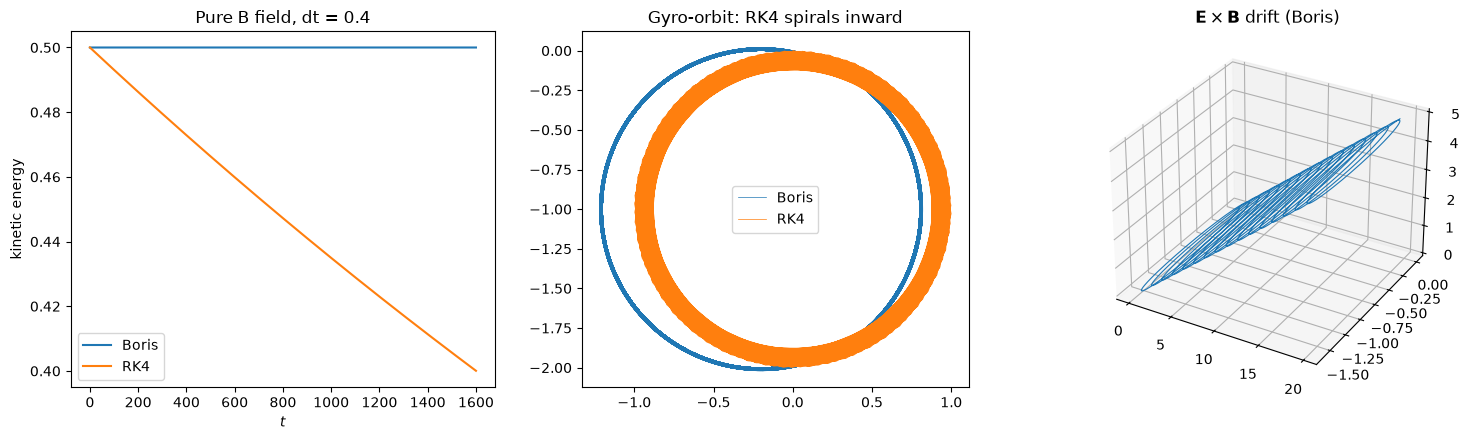

E x B drift speed measured: 0.1958, theory E/B = 0.2


In [4]:
def boris(x0, v0, E_func, B_func, q_m, dt, n_steps):
    x = np.zeros((n_steps + 1, 3)); v = np.zeros_like(x)
    x[0], v[0] = x0, v0
    for n in range(n_steps):
        E, B = E_func(x[n]), B_func(x[n])
        v_minus = v[n] + 0.5*q_m*dt*E
        t = 0.5*q_m*dt*B
        s = 2*t/(1 + t @ t)
        v_prime = v_minus + np.cross(v_minus, t)
        v_plus = v_minus + np.cross(v_prime, s)
        v[n+1] = v_plus + 0.5*q_m*dt*E
        x[n+1] = x[n] + dt*v[n+1]
    return x, v

def rk4_lorentz(x0, v0, E_func, B_func, q_m, dt, n_steps):
    f = lambda y: np.concatenate([y[3:], q_m*(E_func(y[:3]) + np.cross(y[3:], B_func(y[:3])))])
    y = np.zeros((n_steps + 1, 6)); y[0] = np.concatenate([x0, v0])
    for n in range(n_steps):
        k1 = f(y[n]); k2 = f(y[n] + dt/2*k1); k3 = f(y[n] + dt/2*k2); k4 = f(y[n] + dt*k3)
        y[n+1] = y[n] + dt/6*(k1 + 2*k2 + 2*k3 + k4)
    return y[:, :3], y[:, 3:]

# Dimensionless units: q/m = 1, |B| = 1 so the gyro-period is 2 pi.
B_uniform = lambda x: np.array([0.0, 0.0, 1.0])
E_zero = lambda x: np.zeros(3)
E_cross = lambda x: np.array([0.0, 0.2, 0.0])          # gives an E x B drift along x

dt, n = 0.4, 4000                                       # a coarse step: ~16 steps per gyration
x_b, v_b = boris([0, 0, 0], [1, 0, 0], E_zero, B_uniform, 1.0, dt, n)
x_r, v_r = rk4_lorentz([0, 0, 0], [1, 0, 0], E_zero, B_uniform, 1.0, dt, n)
x_d, _ = boris([0, 0, 0], [1, 0, 0.05], E_cross, B_uniform, 1.0, 0.05, 2000)

fig = plt.figure(figsize=(15, 4.5))
ax1 = fig.add_subplot(1, 3, 1)
ax1.plot(np.arange(n + 1)*dt, np.sum(v_b**2, 1)/2, label='Boris')
ax1.plot(np.arange(n + 1)*dt, np.sum(v_r**2, 1)/2, label='RK4')
ax1.set_xlabel('$t$'); ax1.set_ylabel('kinetic energy'); ax1.legend(); ax1.set_title(f'Pure B field, dt = {dt}')
ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(x_b[:, 0], x_b[:, 1], lw=0.5, label='Boris'); ax2.plot(x_r[:, 0], x_r[:, 1], lw=0.5, label='RK4')
ax2.set_aspect('equal'); ax2.legend(); ax2.set_title('Gyro-orbit: RK4 spirals inward')
ax3 = fig.add_subplot(1, 3, 3, projection='3d')
ax3.plot(*x_d.T, lw=0.8); ax3.set_title(r'$\mathbf{E}\times\mathbf{B}$ drift (Boris)')
plt.tight_layout(); plt.show()
print(f'E x B drift speed measured: {(x_d[-1, 0] - x_d[0, 0])/(2000*0.05):.4f}, theory E/B = 0.2')

# A6.3 A magnetic bottle <a class="anchor" id="bottle"></a>
A field that is weak in the middle and strong at the ends can trap charged particles: as a particle spirals into the stronger field, its magnetic moment $\mu = mv_\perp^2/2B$ stays (approximately) constant, so $v_\perp$ grows and, since energy is conserved, $v_\parallel$ must shrink - the particle is **reflected**. This is how the Earth's Van Allen belts trap particles from the solar wind, and was an early approach to fusion confinement.

Particles whose pitch angle at the centre is too small - inside the **loss cone** $\sin^2\alpha < B_\text{min}/B_\text{max}$ - escape through the ends.

We use a field $B_z = B_0(1 + z^2/L^2)$, with the radial component $B_r = -\frac{r}{2}\partial_zB_z$ required by $\nabla\cdot\mathbf B = 0$.

mirror ratio = 5.0  ->  loss-cone angle = 26.6 degrees


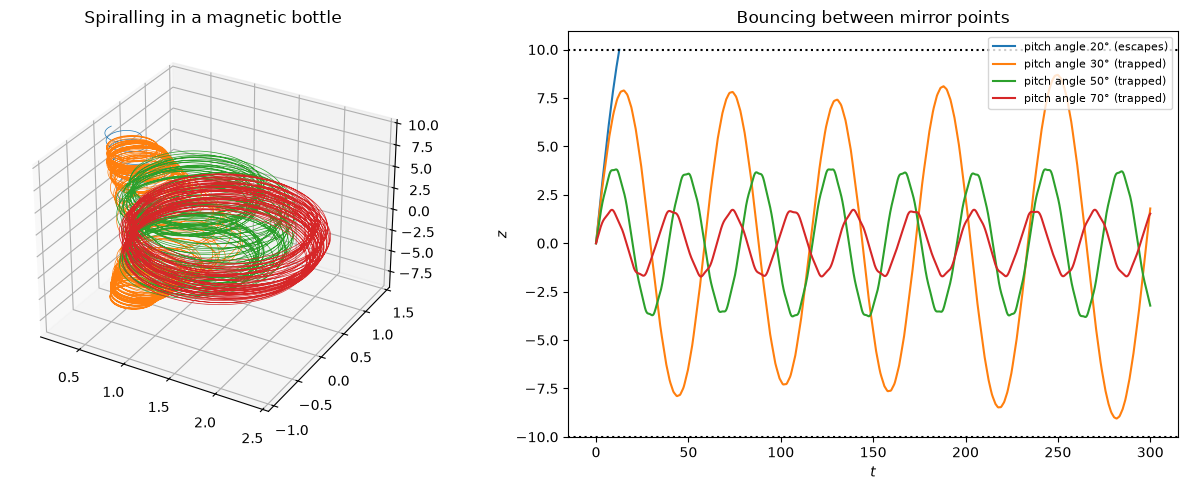

In [5]:
B0, Lb = 1.0, 5.0
def B_bottle(x):
    Bz = B0*(1 + x[2]**2/Lb**2)
    dBz = 2*B0*x[2]/Lb**2
    return np.array([-0.5*x[0]*dBz, -0.5*x[1]*dBz, Bz])

z_max = 10.0                                              # the "mirror points" of our finite bottle
ratio = B_bottle(np.array([0, 0, z_max]))[2]/B0
alpha_loss = np.degrees(np.arcsin(np.sqrt(1/ratio)))
print(f'mirror ratio = {ratio:.1f}  ->  loss-cone angle = {alpha_loss:.1f} degrees')

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax2 = fig.add_subplot(1, 2, 2)
for alpha in [20, 30, 50, 70]:
    a = np.radians(alpha)
    x, v = boris([0.5, 0, 0], [0, np.sin(a), np.cos(a)], E_zero, B_bottle, 1.0, 0.02, 15000)
    out = np.where(np.abs(x[:, 2]) > z_max)[0]
    end = out[0] if len(out) else len(x)
    trapped = 'escapes' if len(out) else 'trapped'
    ax.plot(*x[:end].T, lw=0.5)
    ax2.plot(np.arange(end)*0.02, x[:end, 2], label=f'pitch angle {alpha}° ({trapped})')
ax.set_title('Spiralling in a magnetic bottle')
ax2.axhline(z_max, color='k', ls=':'); ax2.axhline(-z_max, color='k', ls=':')
ax2.set_xlabel('$t$'); ax2.set_ylabel('$z$'); ax2.legend(fontsize=8); ax2.set_title('Bouncing between mirror points')
plt.tight_layout(); plt.show()

# A6.4 Capacitance with a sparse Poisson solver <a class="anchor" id="capacitor"></a>
In Chapter 7 we solved Laplace's equation by relaxation. For a 2D grid of $N\times N$ unknowns, the 5-point Laplacian is a sparse $N^2\times N^2$ matrix with at most 5 non-zeros per row. Building it with **Kronecker products**,

$$\nabla^2 \approx D_2\otimes I + I\otimes D_2,$$

where $D_2$ is the 1D tridiagonal $1,-2,1$ matrix, and solving with a sparse direct solver (`spsolve`) is far faster than relaxation.

Conductors are handled by forcing the rows of fixed-potential points to read $\phi_i = V_i$. We then find the charge on a plate from Gauss's law, $Q = \varepsilon_0\oint\mathbf E\cdot d\mathbf a$, and the capacitance $C = Q/\Delta V$ (per unit length, since this is a 2D problem). The ideal parallel-plate formula $C=\varepsilon_0 w/d$ ignores **fringing fields**; our numerical answer includes them.

capacitance per unit length: 52.0 pF/m   (ideal eps0 w/d = 35.4 pF/m)


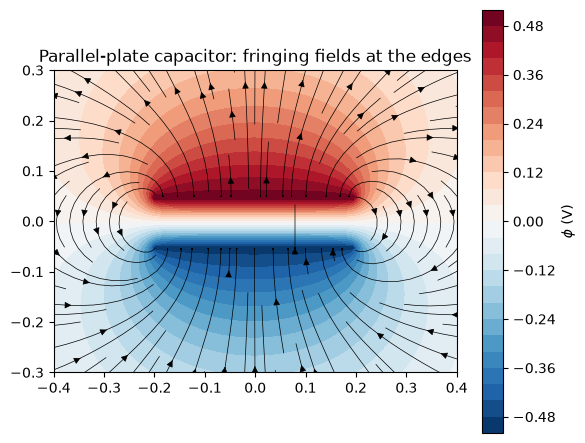

In [6]:
def solve_capacitor(n=201, size=1.0, w=0.4, d=0.1, thickness=2):
    h = size/(n - 1)
    x = np.linspace(-size/2, size/2, n)
    X, Y = np.meshgrid(x, x, indexing='ij')
    fixed = np.zeros((n, n), bool); V = np.zeros((n, n))
    fixed[0, :] = fixed[-1, :] = fixed[:, 0] = fixed[:, -1] = True           # grounded box
    top = (np.abs(X) <= w/2) & (np.abs(Y - d/2) < thickness*h/2)
    bot = (np.abs(X) <= w/2) & (np.abs(Y + d/2) < thickness*h/2)
    fixed |= top | bot; V[top] = 0.5; V[bot] = -0.5

    D2 = sparse.diags([1.0, -2.0, 1.0], [-1, 0, 1], shape=(n, n))
    A = (sparse.kron(D2, sparse.identity(n)) + sparse.kron(sparse.identity(n), D2)).tolil()
    b = np.zeros(n*n)
    idx = np.flatnonzero(fixed)
    A[idx, :] = 0                                     # replace fixed rows with phi_i = V_i
    A[idx, idx] = 1
    b[idx] = V.ravel()[idx]
    phi = spsolve(A.tocsr(), b).reshape(n, n)

    # charge on the top plate: flux of E through a rectangle surrounding it
    Ex, Ey = np.gradient(-phi, h)
    i0, i1 = np.searchsorted(x, -w/2 - 0.03), np.searchsorted(x, w/2 + 0.03)
    j0, j1 = np.searchsorted(x, d/2 - 0.03), np.searchsorted(x, d/2 + 0.03)
    flux = (np.sum(Ey[i0:i1, j1]) - np.sum(Ey[i0:i1, j0]) + np.sum(Ex[i1, j0:j1]) - np.sum(Ex[i0, j0:j1]))*h
    C = eps0*flux/1.0                                  # Delta V = 1 volt
    return x, phi, Ex, Ey, C

x, phi, Ex, Ey, C = solve_capacitor()
print(f'capacitance per unit length: {C*1e12:.1f} pF/m   (ideal eps0 w/d = {eps0*0.4/0.1*1e12:.1f} pF/m)')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cs = ax.contourf(x, x, phi.T, levels=30, cmap='RdBu_r'); fig.colorbar(cs, label=r'$\phi$ (V)')
ax.streamplot(x, x, Ex.T, Ey.T, color='k', density=1.3, linewidth=0.5)
ax.set_xlim(-0.4, 0.4); ax.set_ylim(-0.3, 0.3); ax.set_aspect('equal')
ax.set_title('Parallel-plate capacitor: fringing fields at the edges'); plt.show()

The fringing fields and the outer surfaces of the plates add significantly to the capacitance. As a check, make the plates wider and closer (Project 3) - the ratio to the ideal formula should approach 1.

# A6.5 Light in a box: the FDTD method for Maxwell's equations <a class="anchor" id="fdtd"></a>
The **finite-difference time-domain** (FDTD) method, invented by Kane Yee in 1966, is the workhorse for simulating antennas, photonic crystals, radar and nano-optics. In 1D, for a wave travelling along $x$ with fields $E_y$ and $H_z$:

$$\varepsilon\frac{\partial E_y}{\partial t} = \frac{\partial H}{\partial x},\qquad \mu_0\frac{\partial H}{\partial t} = \frac{\partial E_y}{\partial x},$$

where for neat symmetric equations we have written $H = -H_z$.

Yee's insight was to **stagger** the grids: $E$ lives on integer grid points and integer time steps, $H$ on half-integer points and half-integer times. Each field is then updated from a *central* difference of the other - a leapfrog scheme like the one for the wave equation in Chapter 7, with the same CFL condition $c\Delta t\le\Delta x$.

We send a Gaussian pulse from air onto a glass slab ($n=1.5$) and check the reflected amplitude against the Fresnel coefficient $r = \frac{n_1-n_2}{n_1+n_2} = -0.2$.

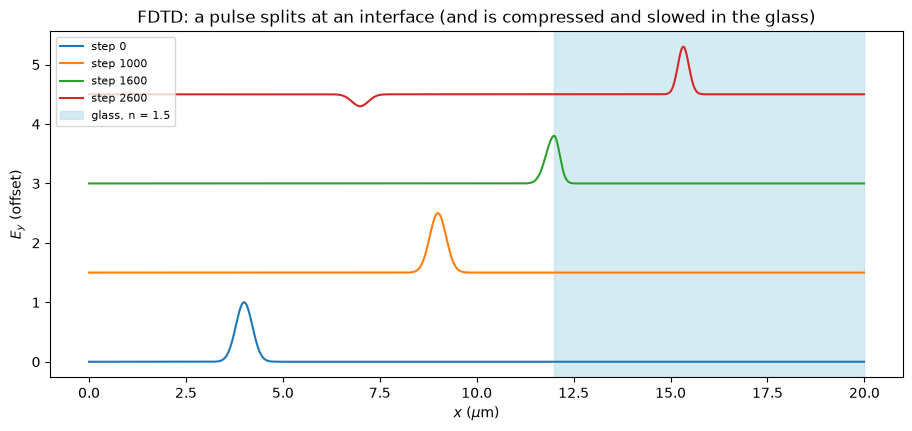

reflection coefficient   r = -0.200  (Fresnel: -0.200)
transmission coefficient t = +0.800  (Fresnel: +0.800)


In [7]:
c0 = 1/np.sqrt(mu0*eps0)
eta0 = np.sqrt(mu0/eps0)                       # impedance of free space, ~377 ohm
Nx = 2000
dx = 10e-9                                     # 10 nm cells
dt = 0.5*dx/c0                                 # Courant number 0.5: light moves half a cell per step
x = np.arange(Nx)*dx
n_glass = 1.5
eps_r = np.ones(Nx); eps_r[1200:] = n_glass**2   # glass from cell 1200 onwards

# Launch a single right-moving Gaussian pulse centred on cell 400. For a right-moving wave 
# H = -Ey/eta0 (H = -H_z as defined above); H lives half a cell to the right and half a step earlier than E.
x0, w = 400*dx, 30*dx
Ey = np.exp(-((x - x0)/w)**2)
x_half = x[:-1] + dx/2
H = -np.exp(-((x_half + c0*dt/2 - x0)/w)**2)/eta0

snapshots = {0: Ey.copy()}
for step in range(1, 2601):
    H += dt/(mu0*dx)*(Ey[1:] - Ey[:-1])                       # H at half steps
    Ey[1:-1] += dt/(eps0*eps_r[1:-1]*dx)*(H[1:] - H[:-1])    # E at whole steps (ends fixed at 0)
    if step in (1000, 1600, 2600):
        snapshots[step] = Ey.copy()

fig, ax = plt.subplots(figsize=(11, 4.5))
for k, (step, E) in enumerate(snapshots.items()):
    ax.plot(x*1e6, E + 1.5*k, label=f'step {step}')
ax.axvspan(x[1200]*1e6, x[-1]*1e6, color='lightblue', alpha=0.5, label='glass, n = 1.5')
ax.set_xlabel(r'$x$ ($\mu$m)'); ax.set_ylabel('$E_y$ (offset)'); ax.legend(loc='upper left', fontsize=8)
ax.set_title('FDTD: a pulse splits at an interface (and is compressed and slowed in the glass)'); plt.show()

E_late = snapshots[2600]
reflected = E_late[:1200][np.argmax(np.abs(E_late[:1200]))]
transmitted = E_late[1200:][np.argmax(np.abs(E_late[1200:]))]
print(f'reflection coefficient   r = {reflected:+.3f}  (Fresnel: {(1 - n_glass)/(1 + n_glass):+.3f})')
print(f'transmission coefficient t = {transmitted:+.3f}  (Fresnel: {2/(1 + n_glass):+.3f})')

Both coefficients come out right, including the **sign flip** of the reflected pulse (reflection off a denser medium). Notice too that the transmitted pulse is narrower: it travels at $c/n$, so it is squeezed by a factor $n$.

The ends of our grid hold $E_y=0$, which makes them perfect mirrors (like a metal wall), so if you run longer the pulses bounce back. Real FDTD codes surround the domain with absorbing boundary layers (*perfectly matched layers*, PML) to mimic open space - see Project 5.

# Projects <a class="anchor" id="projects"></a>

1. **Anti-Helmholtz coils.** Reverse the current in one coil. Show that the field is zero at the centre and grows linearly in every direction - the quadrupole trap used for laser-cooled atoms in a magneto-optical trap.
2. **The Earth's radiation belts.** Model the Earth's field as a dipole $\mathbf B = \frac{\mu_0}{4\pi}\frac{3(\mathbf m\cdot\hat r)\hat r - \mathbf m}{r^3}$ and use the Boris pusher to follow a 10 MeV proton (use relativistic momentum!) launched at 2 Earth radii. Identify the three motions: gyration, bounce between the poles, and slow longitudinal drift around the Earth.
3. **Fringing fields.** Use `solve_capacitor` to compute $C/(\varepsilon_0w/d)$ as a function of $w/d$ and compare with the classic edge-correction formula of Palmer, $C\approx\varepsilon_0\frac{w}{d}\left[1+\frac{d}{\pi w}\left(1+\ln\frac{2\pi w}{d}\right)\right]$.
4. **An anti-reflection coating in FDTD.** Add a quarter-wave layer of $n=\sqrt{1.5}$ in front of the glass and show that a pulse with the right central wavelength is barely reflected. Compare with the transfer-matrix results of the Optics notebook.
5. **A Mur absorbing boundary.** Implement the first-order absorbing boundary $E_0^{n+1} = E_1^n + \frac{c\Delta t - \Delta x}{c\Delta t+\Delta x}(E_1^{n+1}-E_0^n)$ at both ends of the FDTD grid and show that pulses now leave without reflecting.

In [8]:
# Start working here

In [9]:
print("Maxwell wrote 20 equations in 20 unknowns; Heaviside boiled them down to the 4 that now fit on a T-shirt.")  # easter egg (deliberate)

Maxwell wrote 20 equations in 20 unknowns; Heaviside boiled them down to the 4 that now fit on a T-shirt.
